<a href="https://colab.research.google.com/github/gkpremalatha93-ui/ROC/blob/main/ECG_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'sklearn': '1.6.1', 'xgboost': '3.4.1', 'numpy': '2.4.6', 'device': 'cuda', 'gpu': 'Tesla T4', 'cpu_count': 2}
morph (4999, 2, 9) | tab (4999, 12) | all (4999, 30)
{
  "file": "ECG arrythmia dataset.xlsx",
  "n_beats": 4999,
  "n_columns_raw": 33,
  "classes": {
    "N": 4436,
    "VEB": 563
  },
  "abnormal_pct": 11.26,
  "n_continuous_recordings": 2,
  "recording_sizes": [
    2755,
    2244
  ],
  "VEB_per_recording": [
    344,
    219
  ],
  "n_blocks": 20,
  "VEB_per_block_min_max": [
    3,
    49
  ],
  "n_features_all": 30,
  "missing_values": 0,
  "duplicate_rows": 0,
  "pre_RR_range_samples": [
    90,
    276
  ]
}
   Component                                                                                                                                                                                              Specification #Parameters
       C-CNN                                                                              

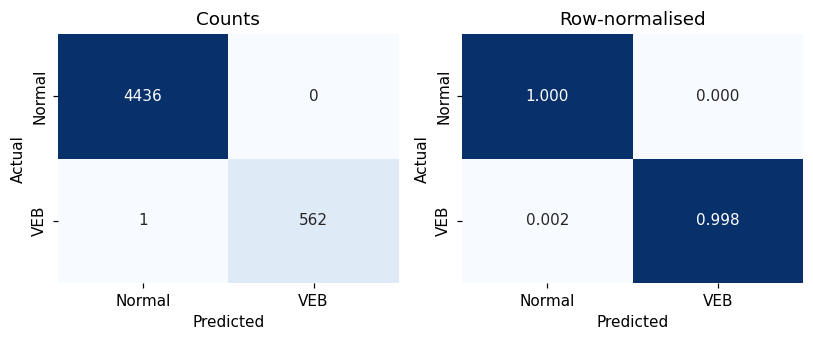

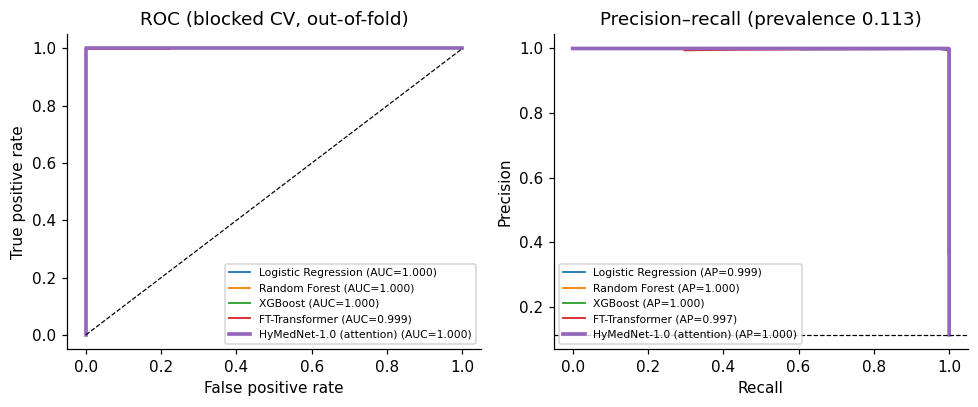

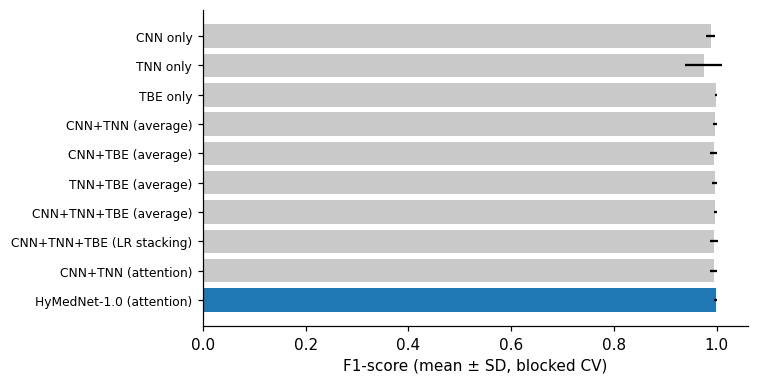

             baseline      metric  mean_diff  CI95_low  CI95_high       t  df  p_NB_ttest  p_wilcoxon  only_HyMedNet_correct  only_baseline_correct  p_McNemar  p_NB_ttest_Holm  p_wilcoxon_Holm  p_McNemar_Holm
LR (RR features only)          f1     0.1022    0.0147     0.1898  2.5043  14      0.0253      0.0010                    133                      1     0.0000           0.2020           0.0079          0.0000
  Logistic Regression          f1     0.0062   -0.0027     0.0151  1.4841  14      0.1599      0.0069                      9                      1     0.0215           0.6397           0.0276          0.1074
            SVM (RBF)          f1     0.0036   -0.0009     0.0081  1.7302  14      0.1056      0.0033                      5                      0     0.0625           0.5592           0.0167          0.2500
        Random Forest          f1     0.0004   -0.0028     0.0036  0.2652  14      0.7947      0.4631                      0                      0     1.0000      

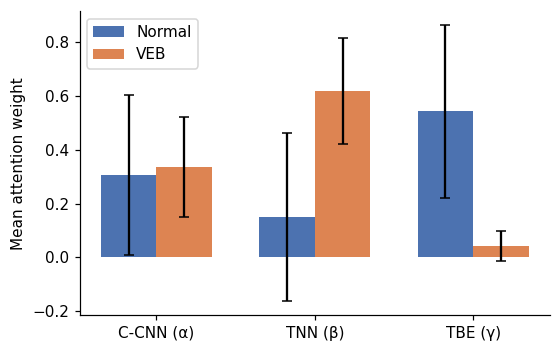

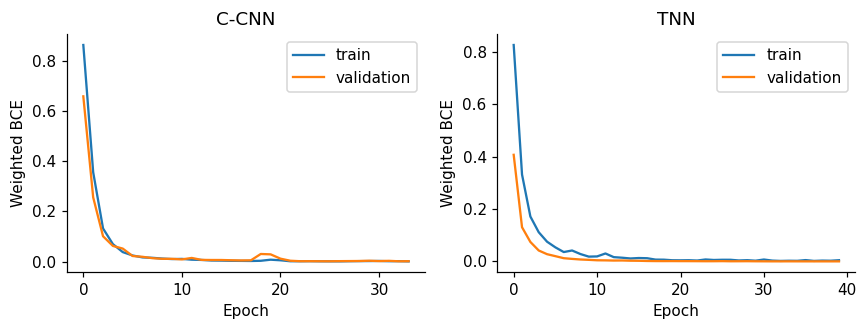

Fold-0 ensemble train vs held-out:
      train  held-out
F1     1.0     0.995
AUC    1.0     1.000


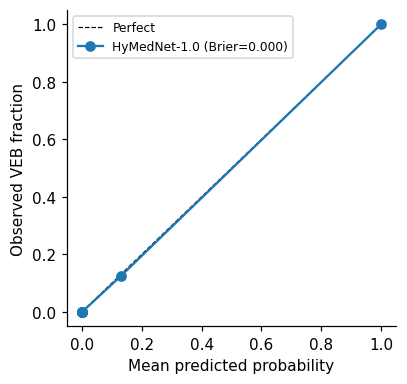

pre_RR             4.7880
L1_rPeak           2.1539
L0_sPeak           0.9616
L1_sPeak           0.5062
L1_st_interval     0.1375
post_RR            0.1071
L1_qPeak           0.0950
L1_qrs_interval    0.0523
L0_qrs_morph3      0.0388
L1_pPeak           0.0366
dtype: float32


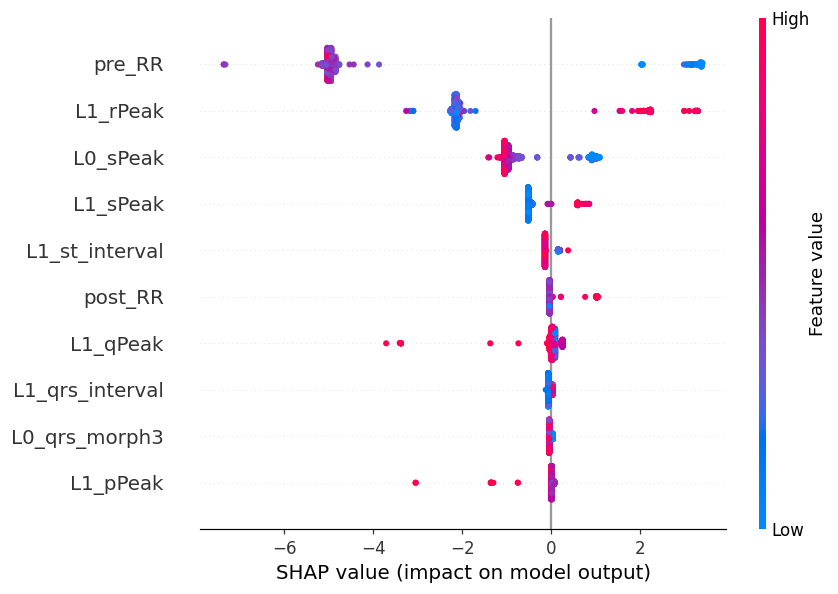

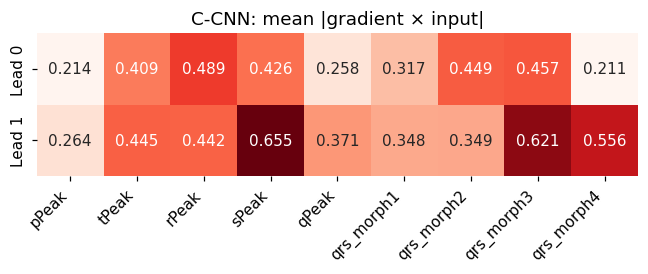

--- blocked ---
      beats  VEB  missed_VEB  false_alarms
rec                                      
0     2755  344           0             0
1     2244  219           1             0 
                        beats  VEB  missed_VEB  false_alarms
RR_ratio_bin                                               
<0.6 (very premature)    549  425           0             0
0.6–0.8                   12    6           1             0
0.8–1.25 (regular)      3462  131           0             0
1.25–1.6                 627    1           0             0
>1.6 (long pause)        349    0           0             0 
Features where MISSED VEBs differ most from DETECTED VEBs (z-score difference):
 L0_qrs_morph4     2.67
L0_qrs_morph3     2.39
L0_qrs_morph2     2.02
L0_rPeak          1.88
L1_st_interval    1.77
L1_rPeak         -1.52
L1_qrs_morph2    -1.37
L0_qrs_morph1     1.34
dtype: float64
--- _LORO ---
      beats  VEB  missed_VEB  false_alarms
rec                                      
0     2755  3

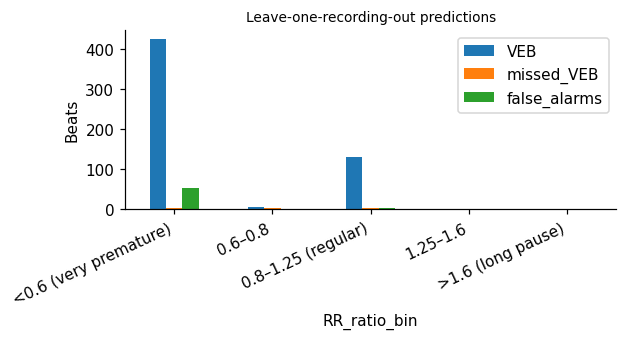

       median_ms  IQR_low  IQR_high
C-CNN      1.076    0.996     1.222
TNN        0.565    0.514     0.636
TBE       44.505   43.799    47.563
Meta       0.471    0.422     0.530
Total     46.596   45.876    50.817 
Hardware: Tesla T4 (features are pre-extracted; extraction time not included)
Baseline single-sample latency (ms): {'RandomForest': 50.224, 'XGBoost': 0.605}
Parameters — C-CNN: 10225 TNN: 18305 Meta: 164 FT-Transformer: 19073
Saved 32 files -> /content/hymednet_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q shap xgboost statsmodels openpyxl
import os, time, json, random, warnings, zipfile, platform
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from scipy import stats
from scipy.stats import binomtest
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

# Automatically correct the dataset path if the uploaded file has spaces instead of underscores
default_path = "/content/ECG_arrythmia_dataset.xlsx"
space_path = "/content/ECG arrythmia dataset.xlsx"
actual_path = space_path if os.path.exists(space_path) else default_path

CFG = dict(
    DATA_PATH   = os.environ.get("DATA_PATH", actual_path),
    BLOCK       = 250,
    N_SPLITS    = 5, REPEATS_BLOCKED = 3, REPEATS_RANDOM = 2, INNER_SPLITS = 3,
    EPOCHS      = 60, PATIENCE = 8, BATCH = 128, LR = 1e-3, WD = 1e-4,
    META_EPOCHS = 300, META_LR = 1e-2, N_TREES = 200,
        SEED        = 42, FAST = False,          # FAST=True = quick test only
    OUT         = os.environ.get("OUT_DIR", "/content/outputs"),
)
if CFG["FAST"]: CFG.update(N_SPLITS=3, REPEATS_BLOCKED=1, REPEATS_RANDOM=1, INNER_SPLITS=2, EPOCHS=3, META_EPOCHS=50, N_TREES=50)
os.makedirs(CFG["OUT"], exist_ok=True)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
def savefig(name): plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/{name}.png", bbox_inches="tight"); plt.show()
import xgboost, sklearn
env = dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__, xgboost=xgboost.__version__, numpy=np.__version__,
           device=str(DEV), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only", cpu_count=os.cpu_count())
print(env)
if not os.path.exists(CFG["DATA_PATH"]):
    print("Please select and upload 'ECG_arrythmia_dataset.xlsx' using the button below:")
    from google.colab import files
    up = files.upload(); CFG["DATA_PATH"] = "/content/" + list(up)[0]
raw = pd.read_excel(CFG["DATA_PATH"]); raw = raw.drop(columns=[c for c in raw if str(c).startswith("Unnamed")]).reset_index(drop=True)
y = (raw["type"] != "N").astype(int).values; BT = raw["type"].values; N = len(y)
MORPH = ["pPeak", "tPeak", "rPeak", "sPeak", "qPeak", "qrs_morph1", "qrs_morph2", "qrs_morph3", "qrs_morph4"]
INTV = ["qrs_interval", "pq_interval", "qt_interval", "st_interval"]
X_morph = np.stack([raw[[f"{l}_{c}" for c in MORPH]].values for l in (0, 1)], 1).astype(np.float32)          # (N,2,9)
pre, post = raw["0_pre-RR"].values.astype(float), raw["0_post-RR"].values.astype(float)
tab = pd.DataFrame({"pre_RR": pre, "post_RR": post, "RR_ratio": pre / post, "RR_mean": (pre + post) / 2})
for l in (0, 1):
    for c in INTV: tab[f"L{l}_{c}"] = raw[f"{l}_{c}"].values
X_tab = tab.values.astype(float); TAB_NAMES = list(tab.columns)
allf = pd.concat([tab, pd.DataFrame({f"L{l}_{c}": raw[f"{l}_{c}"] for l in (0, 1) for c in MORPH})], axis=1)
X_all = allf.values.astype(float); ALL_NAMES = list(allf.columns)
# recordings are recovered from the RR chain; blocks = contiguous windows of BLOCK beats
brk = np.r_[False, post[:-1] != pre[1:]]; REC = np.cumsum(brk); BLK = np.arange(N) // CFG["BLOCK"]
print("morph", X_morph.shape, "| tab", X_tab.shape, "| all", X_all.shape)
desc = dict(file=os.path.basename(CFG["DATA_PATH"]), n_beats=int(N), n_columns_raw=int(raw.shape[1]), classes=pd.Series(BT).value_counts().to_dict(),
            abnormal_pct=round(100 * y.mean(), 2), n_continuous_recordings=int(REC.max() + 1),
            recording_sizes=pd.Series(REC).value_counts().sort_index().tolist(),
            VEB_per_recording=[int(y[REC == r].sum()) for r in np.unique(REC)], n_blocks=int(BLK.max() + 1),
            VEB_per_block_min_max=[int(pd.Series(y).groupby(BLK).sum().min()), int(pd.Series(y).groupby(BLK).sum().max())],
            n_features_all=len(ALL_NAMES), missing_values=int(raw.drop(columns="type").isna().sum().sum()), duplicate_rows=int(raw.duplicated().sum()),
            pre_RR_range_samples=[int(pre.min()), int(pre.max())])
print(json.dumps(desc, indent=2)); json.dump(desc, open(f"{CFG['OUT']}/dataset_description.json", "w"), indent=2)
pd.DataFrame(raw.drop(columns="type").describe().T).round(4).to_csv(f"{CFG['OUT']}/table_feature_summary.csv")
class CCNN(nn.Module):      # morphology branch
    def __init__(s, drop=0.2):
        super().__init__(); ch = [2, 16, 32, 64]
        s.convs = nn.ModuleList([nn.Sequential(nn.Conv1d(ch[i], ch[i+1], 3, padding=1), nn.BatchNorm1d(ch[i+1]), nn.ReLU()) for i in range(3)])
        s.fc = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Dropout(drop)); s.out = nn.Linear(32, 1)
    def forward(s, x):
        for c in s.convs: x = c(x)
        return s.out(s.fc(x.mean(-1))).squeeze(-1)
class TNN(nn.Module):
    def __init__(s, d, drop=0.3):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Dropout(drop), nn.Linear(128, 128), nn.ReLU(), nn.Dropout(drop), nn.Linear(128, 1))
    def forward(s, x): return s.net(x).squeeze(-1)
class FTTransformer(nn.Module):
    def __init__(s, d, dm=32):
        super().__init__(); s.w = nn.Parameter(torch.randn(d, dm) * .1); s.b = nn.Parameter(torch.zeros(d, dm)); s.cls = nn.Parameter(torch.randn(1, 1, dm) * .1)
        s.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(dm, 4, 64, 0.1, batch_first=True), 2); s.out = nn.Linear(dm, 1)
    def forward(s, x):
        t = x.unsqueeze(-1) * s.w + s.b; t = torch.cat([s.cls.expand(len(x), -1, -1), t], 1); return s.out(s.enc(t)[:, 0]).squeeze(-1)
class AttnMeta(nn.Module):
    def __init__(s, k):
        super().__init__(); s.att = nn.Sequential(nn.Linear(2 * k, 16), nn.ReLU(), nn.Linear(16, k)); s.b = nn.Parameter(torch.zeros(1))
    def weights(s, z): return torch.softmax(s.att(torch.cat([z, 2 * torch.abs(torch.sigmoid(z) - .5)], 1)), 1)
    def forward(s, z): return (s.weights(z) * z).sum(1) + s.b
n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
hp = pd.DataFrame([
    ["C-CNN", "3 x [Conv1d(k=3; 16/32/64 filters) + BN + ReLU], global-avg-pool, FC32, dropout 0.2; input 2 leads x 9 morphology descriptors", n_params(CCNN())],
    ["TNN", f"FC128-FC128, dropout 0.3; input {X_tab.shape[1]} interval/rhythm attributes", n_params(TNN(X_tab.shape[1]))],
    ["TBE", f"RandomForest({CFG['N_TREES']} trees, depth 10, balanced) + XGBoost({CFG['N_TREES']} trees, lr 0.1, depth 6); probabilities averaged; input {X_all.shape[1]} features", "n/a"],
    ["Meta-learner", "softmax attention MLP (2k->16->k) over branch logits; fused logit = sum w_i z_i + b", n_params(AttnMeta(3))],
    ["Optimisation", f"Adam lr={CFG['LR']}, weight decay={CFG['WD']}, batch={CFG['BATCH']}, <= {CFG['EPOCHS']} epochs, early stopping (patience {CFG['PATIENCE']}, validation loss), class-weighted BCE (pos_weight = n_neg/n_pos); meta-learner Adam lr={CFG['META_LR']}, {CFG['META_EPOCHS']} full-batch epochs", ""]],
    columns=["Component", "Specification", "#Parameters"])
hp.to_csv(f"{CFG['OUT']}/table_hyperparameters.csv", index=False); print(hp.to_string(index=False))
logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4))); sigm = lambda z: 1 / (1 + np.exp(-z)); T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
@torch.no_grad()
def predict_logit(m, X, bs=4096): m.eval().to(DEV); return np.concatenate([m(X[i:i+bs].to(DEV)).cpu().numpy() for i in range(0, len(X), bs)])
def train_nn(model, Xtr, ytr, Xva, yva):
    model.to(DEV); opt = torch.optim.Adam(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WD"])
    lf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1), dtype=torch.float32, device=DEV)); yt, yv = T(ytr), T(yva)
    best, state, bad, hist = 1e9, None, 0, dict(train=[], val=[])
    for ep in range(CFG["EPOCHS"]):
        model.train(); perm = torch.randperm(len(Xtr)); tl = 0
        for i in range(0, len(Xtr), CFG["BATCH"]):
            b = perm[i:i + CFG["BATCH"]]
            if len(b) < 2: continue
            opt.zero_grad(); loss = lf(model(Xtr[b].to(DEV)), yt[b].to(DEV)); loss.backward(); opt.step(); tl += loss.item() * len(b)
        model.eval()
        with torch.no_grad(): vl = lf(model(Xva.to(DEV)), yv.to(DEV)).item()
        hist["train"].append(tl / len(Xtr)); hist["val"].append(vl)
        if vl < best - 1e-4: best, bad, state = vl, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["PATIENCE"]: break
    if state: model.load_state_dict(state)
    return model, hist
def fit_attn(Z, yy):
    m = AttnMeta(Z.shape[1]).to(DEV); opt = torch.optim.Adam(m.parameters(), lr=CFG["META_LR"], weight_decay=1e-3)
    Zt, yt = T(np.clip(Z, -10, 10)).to(DEV), T(yy).to(DEV); lf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((yy == 0).sum() / max((yy == 1).sum(), 1), dtype=torch.float32, device=DEV))
    for _ in range(CFG["META_EPOCHS"]): opt.zero_grad(); lf(m(Zt), yt).backward(); opt.step()
    return m.eval()
@torch.no_grad()
def attn_apply(m, Z): Zt = T(np.clip(Z, -10, 10)).to(DEV); return m(Zt).cpu().numpy(), m.weights(Zt).cpu().numpy()
def split_val(idx, seed):
    a, b = next(GroupShuffleSplit(1, test_size=0.15, random_state=seed).split(idx, groups=BLK[idx])); return idx[a], idx[b]
def tbe_models(pos_w):
    return (XGBClassifier(n_estimators=CFG["N_TREES"], learning_rate=.1, max_depth=6, subsample=.9, colsample_bytree=.9, n_jobs=-1, verbosity=0, scale_pos_weight=pos_w, random_state=0),
            RandomForestClassifier(CFG["N_TREES"], max_depth=10, class_weight="balanced", n_jobs=-1, random_state=0))
class Bases:
    def __init__(s, tr, seed):
        seed_all(seed); s.m_sc, s.t_sc, s.a_sc = [StandardScaler().fit(a[tr].reshape(len(tr), -1)) for a in (X_morph, X_tab, X_all)]
        fi, vi = split_val(tr, seed)
        s.cnn, s.h_cnn = train_nn(CCNN(), s.m(fi), y[fi], s.m(vi), y[vi]); s.tnn, s.h_tnn = train_nn(TNN(X_tab.shape[1]), s.t(fi), y[fi], s.t(vi), y[vi])
        s.xgb, s.rf = tbe_models((y[tr] == 0).sum() / max((y[tr] == 1).sum(), 1)); s.xgb.fit(s.a(tr), y[tr]); s.rf.fit(s.a(tr), y[tr])
    def m(s, i): return T(s.m_sc.transform(X_morph[i].reshape(len(i), -1)).reshape(len(i), 2, -1))
    def t(s, i): return T(s.t_sc.transform(X_tab[i]))
    def a(s, i): return s.a_sc.transform(X_all[i])
    def logits(s, i): return np.c_[predict_logit(s.cnn, s.m(i)), predict_logit(s.tnn, s.t(i)), logit(.5 * (s.xgb.predict_proba(s.a(i))[:, 1] + s.rf.predict_proba(s.a(i))[:, 1]))]
def oof_logits(tr, seed):
    Z = np.zeros((len(tr), 3))
    for a, b in StratifiedGroupKFold(CFG["INNER_SPLITS"], shuffle=True, random_state=seed).split(tr, y[tr], BLK[tr]): Z[b] = Bases(tr[a], seed + 1).logits(tr[b])
    return Z
FULL = "HyMedNet-1.0 (attention)"
def combos(Ztr, ytr, Zte):
    P, W = {}, {}; P["CNN only"], P["TNN only"], P["TBE only"] = sigm(Zte[:, 0]), sigm(Zte[:, 1]), sigm(Zte[:, 2])
    for n, c in {"CNN+TNN (average)": [0, 1], "CNN+TBE (average)": [0, 2], "TNN+TBE (average)": [1, 2], "CNN+TNN+TBE (average)": [0, 1, 2]}.items(): P[n] = sigm(Zte[:, c]).mean(1)
    P["CNN+TNN+TBE (LR stacking)"] = LogisticRegression(class_weight="balanced", max_iter=1000).fit(Ztr, ytr).predict_proba(Zte)[:, 1]
    z, w = attn_apply(fit_attn(Ztr[:, :2], ytr), Zte[:, :2]); P["CNN+TNN (attention)"] = sigm(z)
    m3 = fit_attn(Ztr, ytr); z, w = attn_apply(m3, Zte); P[FULL], W[FULL] = sigm(z), w
    return P, W, m3
def baselines(tr, te, seed):
    P = {}; sc = StandardScaler().fit(X_all[tr]); Xtr, Xte = sc.transform(X_all[tr]), sc.transform(X_all[te]); pw = (y[tr] == 0).sum() / max((y[tr] == 1).sum(), 1)
    P["Logistic Regression"] = LogisticRegression(class_weight="balanced", max_iter=2000).fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
    sc4 = StandardScaler().fit(X_tab[tr][:, :4]); P["LR (RR features only)"] = LogisticRegression(class_weight="balanced", max_iter=2000).fit(sc4.transform(X_tab[tr][:, :4]), y[tr]).predict_proba(sc4.transform(X_tab[te][:, :4]))[:, 1]
    P["SVM (RBF)"] = sigm(SVC(class_weight="balanced").fit(Xtr, y[tr]).decision_function(Xte))
    P["Random Forest"] = RandomForestClassifier(CFG["N_TREES"], max_depth=10, class_weight="balanced", n_jobs=-1, random_state=0).fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
    P["XGBoost"] = XGBClassifier(n_estimators=CFG["N_TREES"], learning_rate=.1, max_depth=6, n_jobs=-1, verbosity=0, scale_pos_weight=pw, random_state=0).fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
    P["MLP"] = MLPClassifier((128, 64), max_iter=300, early_stopping=True, random_state=seed).fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
    fi, vi = split_val(tr, seed); seed_all(seed); Xa = lambda i: T(sc.transform(X_all[i]))
    m, _ = train_nn(FTTransformer(X_all.shape[1]), Xa(fi), y[fi], Xa(vi), y[vi]); P["FT-Transformer"] = sigm(predict_logit(m, Xa(te)))
    return P
def metrics(yt, p, thr=.5):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0, 1]).ravel(); se, sp, pr = tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=(tp + tn) / len(yt), precision=pr, sensitivity=se, specificity=sp, f1=2 * pr * se / max(pr + se, 1e-12),
                auc=roc_auc_score(yt, p) if len(np.unique(yt)) > 1 else np.nan, ap=average_precision_score(yt, p), fnr=fn / max(tp + fn, 1), fpr=fp / max(tn + fp, 1))
def make_splits(scheme):
    out = []; idx = np.arange(N)
    if scheme == "blocked":
        for r in range(CFG["REPEATS_BLOCKED"]):
            for f, (a, b) in enumerate(StratifiedGroupKFold(CFG["N_SPLITS"], shuffle=True, random_state=CFG["SEED"] + 100 * r).split(idx, y, BLK)): out.append((r, f, a, b))
    elif scheme == "random":
        for r in range(CFG["REPEATS_RANDOM"]):
            for f, (a, b) in enumerate(StratifiedKFold(CFG["N_SPLITS"], shuffle=True, random_state=CFG["SEED"] + 100 * r).split(idx, y)): out.append((r, f, a, b))
    elif scheme == "leave-one-recording-out":
        for f, rr in enumerate(np.unique(REC)): out.append((0, f, idx[REC != rr], idx[REC == rr]))
    return out
rows, OOF, ATT, ART = [], {}, {}, {}; t0 = time.time()
for scheme in ["blocked", "leave-one-recording-out", "random"]:
    for rep, fold, tr, te in make_splits(scheme):
        if scheme == "blocked": assert not set(BLK[tr]) & set(BLK[te]), "block leakage"
        if scheme == "leave-one-recording-out": assert not set(REC[tr]) & set(REC[te])
        seed = CFG["SEED"] + 100 * rep + fold; Ztr = oof_logits(tr, seed); B = Bases(tr, seed); Zte = B.logits(te)
        P, W, m3 = combos(Ztr, y[tr], Zte); P.update(baselines(tr, te, seed))
        for name, p in P.items():
            rows.append(dict(scheme=scheme, rep=rep, fold=fold, model=name, n_train=len(tr), n_test=len(te), **metrics(y[te], p)))
            if rep == 0: OOF.setdefault(scheme, {}).setdefault(name, np.full(N, np.nan))[te] = p
        if rep == 0 and scheme == "blocked":
            ATT.setdefault(FULL, np.full((N, 3), np.nan))[te] = W[FULL]
            if fold == 0: ART = dict(B=B, meta=m3, te=te, tr=tr)
        print(f"{scheme:24s} rep {rep} fold {fold}  HyMedNet F1={[r for r in rows if r['model']==FULL][-1]['f1']:.3f}  [{(time.time()-t0)/60:.1f} min]", flush=True)
R = pd.DataFrame(rows); R.to_csv(f"{CFG['OUT']}/per_fold_results.csv", index=False)
np.savez_compressed(f"{CFG['OUT']}/oof_predictions.npz", **{f"{sc}|{m}": v for sc, d in OOF.items() for m, v in d.items()}, attention=ATT[FULL])
RB = R[R.scheme == "blocked"]; OOFB = OOF["blocked"]
ABL = ["CNN only", "TNN only", "TBE only", "CNN+TNN (average)", "CNN+TBE (average)", "TNN+TBE (average)", "CNN+TNN+TBE (average)", "CNN+TNN+TBE (LR stacking)", "CNN+TNN (attention)", FULL]
BASE = ["LR (RR features only)", "Logistic Regression", "SVM (RBF)", "Random Forest", "XGBoost", "MLP", "CNN only", "FT-Transformer", FULL]
MET = ["accuracy", "precision", "sensitivity", "specificity", "f1", "auc"]
def table(models, df=RB):
    g = df[df.model.isin(models)].groupby("model")
    return pd.DataFrame({m: g[m].mean().round(3).astype(str) + " ± " + g[m].std().round(3).astype(str) for m in MET + ["fnr"]}).loc[models]
T_base, T_abl = table(BASE), table(ABL); T_base.to_csv(f"{CFG['OUT']}/table_baselines_blocked_cv.csv"); T_abl.to_csv(f"{CFG['OUT']}/table_ablation_blocked_cv.csv")
print("=== Baselines, blocked CV (mean ± SD over folds×repeats) ===\n", T_base.to_string(), "\n\n=== Ablation ===\n", T_abl.to_string())
prot = pd.DataFrame({s: R[(R.scheme == s) & R.model.isin([FULL, "XGBoost", "Random Forest"])].groupby("model")[["f1", "sensitivity", "specificity", "auc"]].mean().round(3).apply(lambda r: " / ".join(map(str, r)), axis=1) for s in ["random", "blocked", "leave-one-recording-out"]})
prot.index.name = "F1 / Sens / Spec / AUC"; prot.to_csv(f"{CFG['OUT']}/table_protocol_comparison.csv"); print("\n=== Effect of evaluation protocol ===\n", prot.to_string())
pm = metrics(y, OOFB[FULL]); cm = np.array([[pm["TN"], pm["FP"]], [pm["FN"], pm["TP"]]])
print("\nPooled out-of-fold confusion matrix [[TN FP],[FN TP]] =", cm.tolist(), " n =", cm.sum())
rec = dict(accuracy=(pm["TP"] + pm["TN"]) / cm.sum(), precision=pm["TP"] / (pm["TP"].astype(float) + pm["FP"]), sensitivity=pm["TP"] / (pm["TP"].astype(float) + pm["FN"]), specificity=pm["TN"] / (pm["TN"].astype(float) + pm["FP"]), f1=pm["f1"], auc=pm["auc"])
print("Recomputed from the counts:", {k: round(v, 4) for k, v in rec.items()}); pd.DataFrame([{**pm, **{k + "_check": v for k, v in rec.items()}}]).to_csv(f"{CFG['OUT']}/table_pooled_confusion_metrics.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.2))
for a, (M, fmt, ttl) in zip(ax, [(cm, "d", "Counts"), (cm / cm.sum(1, keepdims=True), ".3f", "Row-normalised")]):
    sns.heatmap(M, annot=True, fmt=fmt, cmap="Blues", cbar=False, ax=a, xticklabels=["Normal", "VEB"], yticklabels=["Normal", "VEB"]); a.set(xlabel="Predicted", ylabel="Actual", title=ttl)
savefig("fig_confusion_matrix")
show = ["Logistic Regression", "Random Forest", "XGBoost", "FT-Transformer", FULL]; cols = plt.cm.tab10(np.arange(len(show))); fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for c, m in zip(cols, show):
    fpr, tpr, _ = roc_curve(y, OOFB[m]); pr, rc, _ = precision_recall_curve(y, OOFB[m]); lw = 2.4 if m == FULL else 1.2
    ax[0].plot(fpr, tpr, color=c, lw=lw, label=f"{m} (AUC={roc_auc_score(y, OOFB[m]):.3f})"); ax[1].plot(rc, pr, color=c, lw=lw, label=f"{m} (AP={average_precision_score(y, OOFB[m]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (blocked CV, out-of-fold)"); ax[1].axhline(y.mean(), color="k", ls="--", lw=.8)
ax[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision–recall (prevalence {y.mean():.3f})"); ax[0].legend(fontsize=7, loc="lower right"); ax[1].legend(fontsize=7, loc="lower left"); savefig("fig_roc_pr_comparison")
a = RB[RB.model.isin(ABL)].groupby("model").f1.agg(["mean", "std"]).loc[ABL]; fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(range(len(a)), a["mean"], xerr=a["std"], color=["#c9c9c9"] * (len(a) - 1) + ["#1f77b4"]); ax.set_yticks(range(len(a))); ax.set_yticklabels(a.index, fontsize=8); ax.set_xlabel("F1-score (mean ± SD, blocked CV)"); ax.invert_yaxis(); savefig("fig_ablation")
def nb_t(d, n_te, n_tr):   # Nadeau–Bengio corrected resampled paired t-test
    k = len(d); v = np.var(d, ddof=1)
    if v == 0: return 0., k - 1, 1., (d.mean(), d.mean())
    se = np.sqrt((1 / k + n_te / n_tr) * v); t = d.mean() / se; return t, k - 1, 2 * stats.t.sf(abs(t), k - 1), (d.mean() - stats.t.ppf(.975, k - 1) * se, d.mean() + stats.t.ppf(.975, k - 1) * se)
def sig_table(metric):
    A = RB[RB.model == FULL].sort_values(["rep", "fold"]); res = []
    for m in [b for b in BASE if b != FULL]:
        Bm = RB[RB.model == m].sort_values(["rep", "fold"]); d = (A[metric].values - Bm[metric].values); t, df, p, ci = nb_t(d, A.n_test.iloc[0], A.n_train.iloc[0])
        try: w = stats.wilcoxon(d).pvalue
        except ValueError: w = np.nan
        c1 = ((OOFB[FULL] >= .5) == y)[(OOFB[m] >= .5) != y].sum(); c2 = ((OOFB[m] >= .5) == y)[(OOFB[FULL] >= .5) != y].sum()
        res.append(dict(baseline=m, metric=metric, mean_diff=d.mean(), CI95_low=ci[0], CI95_high=ci[1], t=t, df=df, p_NB_ttest=p, p_wilcoxon=w, only_HyMedNet_correct=int(c1), only_baseline_correct=int(c2), p_McNemar=binomtest(int(min(c1, c2)), int(c1 + c2), .5).pvalue if c1 + c2 else 1.))
    S = pd.DataFrame(res)
    for c in ["p_NB_ttest", "p_wilcoxon", "p_McNemar"]:
        ok = S[c].notna(); S.loc[ok, c + "_Holm"] = multipletests(S.loc[ok, c], method="holm")[1]
    return S
ST = pd.concat([sig_table(m) for m in ["f1", "sensitivity", "auc"]]); ST.to_csv(f"{CFG['OUT']}/table_significance.csv", index=False); print(ST.round(4).to_string(index=False))
rng = np.random.default_rng(0); ub = np.unique(BLK); bi = {b: np.where(BLK == b)[0] for b in ub}; bs = []
for _ in range(1000):
    ii = np.concatenate([bi[b] for b in rng.choice(ub, len(ub))])
    if len(np.unique(y[ii])) < 2: continue
    mm = metrics(y[ii], OOFB[FULL][ii]); bs.append([mm[k] for k in ["accuracy", "sensitivity", "specificity", "f1", "auc"]])
CI = pd.DataFrame(np.percentile(bs, [2.5, 50, 97.5], 0).T, index=["accuracy", "sensitivity", "specificity", "f1", "auc"], columns=["2.5%", "median", "97.5%"]).round(3); CI.to_csv(f"{CFG['OUT']}/table_bootstrap_ci.csv"); print("\nBlock-bootstrap 95% CI, HyMedNet-1.0:\n", CI)
W = ATT[FULL]; assert np.allclose(W.sum(1), 1, atol=1e-5), "attention weights must sum to 1"; nm = ["C-CNN (α)", "TNN (β)", "TBE (γ)"]
AT = pd.DataFrame({c: [f"{W[y == k, j].mean():.3f} ± {W[y == k, j].std():.3f}" for j in range(3)] for c, k in [("Normal", 0), ("VEB", 1)]}, index=nm)
AT.loc["Sum of means"] = [f"{W[y == k].mean(0).sum():.3f}" for k in (0, 1)]; AT.to_csv(f"{CFG['OUT']}/table_attention_weights.csv"); print(AT.to_string())
fig, ax = plt.subplots(figsize=(5.2, 3.3)); pos = np.arange(3)
for off, k, lab, col in [(-.175, 0, "Normal", "#4c72b0"), (.175, 1, "VEB", "#dd8452")]: ax.bar(pos + off, [W[y == k, j].mean() for j in range(3)], .35, yerr=[W[y == k, j].std() for j in range(3)], label=lab, color=col, capsize=3)
ax.set_xticks(pos); ax.set_xticklabels(nm); ax.set_ylabel("Mean attention weight"); ax.legend(); savefig("fig_attention_weights")

B = ART["B"]; fig, ax = plt.subplots(1, 2, figsize=(8, 3.1))
for a, (h, t_) in zip(ax, [(B.h_cnn, "C-CNN"), (B.h_tnn, "TNN")]): a.plot(h["train"], label="train"); a.plot(h["val"], label="validation"); a.set(xlabel="Epoch", ylabel="Weighted BCE", title=t_); a.legend()
savefig("fig_learning_curves"); trm = metrics(y[ART["tr"]], sigm(B.logits(ART["tr"])).mean(1)); tem = RB[(RB.model == "CNN+TNN+TBE (average)") & (RB.rep == 0) & (RB.fold == 0)].iloc[0]
gap = pd.DataFrame({"train": [trm["f1"], trm["auc"]], "held-out": [tem["f1"], tem["auc"]]}, index=["F1", "AUC"]); gap.round(3).to_csv(f"{CFG['OUT']}/table_train_vs_test_gap.csv"); print("Fold-0 ensemble train vs held-out:\n", gap.round(3))
pt, pp = calibration_curve(y, OOFB[FULL], n_bins=10, strategy="quantile"); brier = np.mean((OOFB[FULL] - y) ** 2)
fig, ax = plt.subplots(figsize=(3.8, 3.6)); ax.plot([0, 1], [0, 1], "k--", lw=.8, label="Perfect"); ax.plot(pp, pt, "o-", label=f"HyMedNet-1.0 (Brier={brier:.3f})"); ax.set(xlabel="Mean predicted probability", ylabel="Observed VEB fraction"); ax.legend(fontsize=8); savefig("fig_calibration")
import shap
te = ART["te"]; Xa = B.a(te); sv = shap.TreeExplainer(B.xgb).shap_values(Xa); ms = pd.Series(np.abs(sv).mean(0), index=ALL_NAMES).sort_values(ascending=False)
ms.head(15).round(4).to_csv(f"{CFG['OUT']}/table_shap_top15.csv"); print(ms.head(10).round(4)); plt.figure(figsize=(6, 4)); shap.summary_plot(sv, Xa, feature_names=ALL_NAMES, max_display=10, show=False); savefig("fig_shap_summary")
Xm = B.m(te).clone().to(DEV).requires_grad_(True); B.cnn.eval().to(DEV); B.cnn(Xm).sum().backward(); sal = (Xm.grad * Xm).abs().mean(0).detach().cpu().numpy()
fig, ax = plt.subplots(figsize=(6, 2.6)); sns.heatmap(sal, annot=True, fmt=".3f", cmap="Reds", cbar=False, xticklabels=MORPH, yticklabels=["Lead 0", "Lead 1"], ax=ax); plt.xticks(rotation=45, ha="right"); ax.set_title("C-CNN: mean |gradient × input|"); savefig("fig_cnn_saliency")
def error_analysis(oof, tag):
    pf = (oof[FULL] >= .5).astype(int); E = pd.DataFrame(dict(rec=REC, y=y, pred=pf, pre=pre, post=post)); E["FN"] = (E.y == 1) & (E.pred == 0); E["FP"] = (E.y == 0) & (E.pred == 1)
    by_rec = E.groupby("rec").agg(beats=("y", "size"), VEB=("y", "sum"), missed_VEB=("FN", "sum"), false_alarms=("FP", "sum")); by_rec.to_csv(f"{CFG['OUT']}/table_error_by_recording{tag}.csv")
    E["RR_ratio_bin"] = pd.cut(E.pre / E.post, [0, .6, .8, 1.25, 1.6, 10], labels=["<0.6 (very premature)", "0.6–0.8", "0.8–1.25 (regular)", "1.25–1.6", ">1.6 (long pause)"])
    bins = E.groupby("RR_ratio_bin").agg(beats=("y", "size"), VEB=("y", "sum"), missed_VEB=("FN", "sum"), false_alarms=("FP", "sum")); bins.to_csv(f"{CFG['OUT']}/table_error_by_RR_context{tag}.csv")
    z = pd.DataFrame(StandardScaler().fit_transform(X_all), columns=ALL_NAMES); tp_mask = ((E.y == 1) & (E.pred == 1)).values
    if E.FN.sum() > 0 and tp_mask.sum() > 0:
        fnprof = (z[E.FN.values].mean() - z[tp_mask].mean()).sort_values(key=abs, ascending=False).head(8).round(2)
    else: fnprof = pd.Series(dtype=float)
    fnprof.to_csv(f"{CFG['OUT']}/table_missed_vs_detected_VEB{tag}.csv")
    print(f"--- {tag or 'blocked'} ---\n", by_rec, "\n", bins, "\nFeatures where MISSED VEBs differ most from DETECTED VEBs (z-score difference):\n", fnprof); return bins
bins_blk = error_analysis(OOF["blocked"], "")
bins = error_analysis(OOF["leave-one-recording-out"], "_LORO")
loro_cm = R[(R.scheme == "leave-one-recording-out") & R.model.isin([FULL, "Random Forest", "XGBoost", "TBE only", "FT-Transformer"])][["fold", "model", "TP", "FN", "FP", "TN", "sensitivity", "specificity", "f1"]].round(3)
loro_cm.to_csv(f"{CFG['OUT']}/table_loro_confusion.csv", index=False); print(loro_cm.to_string(index=False))
fig, ax = plt.subplots(figsize=(5.8, 3.2)); bins[["VEB", "missed_VEB", "false_alarms"]].plot.bar(ax=ax); plt.xticks(rotation=25, ha="right"); ax.set_ylabel("Beats"); ax.set_title("Leave-one-recording-out predictions", fontsize=9); savefig("fig_error_by_RR_context")
Bm, i0 = ART["B"], ART["te"][:200]; lat = {k: [] for k in ["C-CNN", "TNN", "TBE", "Meta", "Total"]}
with torch.no_grad():
    for i in i0:
        i = np.array([i]); a = time.perf_counter(); Bm.cnn(Bm.m(i).to(DEV)); t1 = time.perf_counter(); Bm.tnn(Bm.t(i).to(DEV)); t2 = time.perf_counter()
        h = Bm.a(i); Bm.xgb.predict_proba(h); Bm.rf.predict_proba(h); t3 = time.perf_counter(); ART["meta"](T(np.zeros((1, 3))).to(DEV)); t4 = time.perf_counter()
        for k, v in zip(lat, [t1 - a, t2 - t1, t3 - t2, t4 - t3, t4 - a]): lat[k].append(v * 1e3)
LT = pd.DataFrame({k: [np.median(v), np.percentile(v, 25), np.percentile(v, 75)] for k, v in lat.items()}, index=["median_ms", "IQR_low", "IQR_high"]).T.round(3); LT.to_csv(f"{CFG['OUT']}/table_latency.csv"); print(LT.to_string(), "\nHardware:", env["gpu"], "(features are pre-extracted; extraction time not included)")
t_ = {}
for n_, mk in [("RandomForest", lambda: Bm.rf), ("XGBoost", lambda: Bm.xgb)]:
    m_ = mk(); a = time.perf_counter(); [m_.predict_proba(Bm.a(np.array([i]))) for i in i0]; t_[n_] = (time.perf_counter() - a) / len(i0) * 1e3
LT.loc["Random forest alone (mean)"] = [t_["RandomForest"], np.nan, np.nan]; LT.loc["XGBoost alone (mean)"] = [t_["XGBoost"], np.nan, np.nan]; LT.round(3).to_csv(f"{CFG['OUT']}/table_latency.csv")
print("Baseline single-sample latency (ms):", {k: round(v, 3) for k, v in t_.items()}); print("Parameters — C-CNN:", n_params(Bm.cnn), "TNN:", n_params(Bm.tnn), "Meta:", n_params(ART["meta"]), "FT-Transformer:", n_params(FTTransformer(X_all.shape[1])))
json.dump(dict(env=env, dataset=desc, config={k: v for k, v in CFG.items() if k != "OUT"}, pooled_confusion_blocked=cm.tolist(), pooled_metrics_recomputed={k: float(v) for k, v in rec.items()}), open(f"{CFG['OUT']}/results_summary.json", "w"), indent=2, default=str)
zp = "/content/hymednet_outputs.zip" if os.path.isdir("/content") else CFG["OUT"] + ".zip"
with zipfile.ZipFile(zp, "w") as zf:
    for f in sorted(os.listdir(CFG["OUT"])): zf.write(f"{CFG['OUT']}/{f}", f)
print("Saved", len(os.listdir(CFG["OUT"])), "files ->", zp)
try:
    from google.colab import files; files.download(zp)
except Exception: pass